# Pertemuan 10 — Segmentasi Paru pada Citra X-ray dengan U-Net

**Kecerdasan Buatan (BM25-41204) · Teknik Biomedis ITERA** — Martin C.T. Manullang

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mctosima/ai-bm/blob/main/pertemuan-10/segmentasi_paru_unet.ipynb)

Di Pertemuan 9 kita mengajari komputer menebak **satu label untuk satu detak EKG**. Hari ini tugasnya naik level: komputer harus **mewarnai setiap piksel** citra X-ray dada — piksel mana yang termasuk **paru-paru**, piksel mana yang bukan. Tugas ini disebut **segmentasi**.

**Kamu tidak perlu pernah ngoding sebelumnya.** Setiap langkah dijelaskan dengan bahasa sehari-hari.

### Yang akan kamu pelajari
1. Apa bedanya klasifikasi, deteksi, dan segmentasi.
2. Bagaimana mengukur hasil segmentasi dengan **Dice** dan **IoU**.
3. Cara kerja **U-Net** — tanpa rumus yang menakutkan.
4. Apa itu **augmentasi data**, dan kenapa ia bisa menyelamatkan model yang dipakai di rumah sakit lain.

## Cara memakai notebook ini

Sama seperti Pertemuan 9: klik sel kode, tekan **Shift + Enter**, jalankan **berurutan dari atas ke bawah**. Baca komentar yang diawali tanda `#` — di sanalah penjelasan setiap baris.

> **Di Google Colab?** Pakai GPU supaya cepat: menu **Runtime → Change runtime type → T4 GPU → Save**. Tanpa GPU pun tetap jalan (melatih model sekitar 2–3 menit).

---
## Bagian 0 — Cerita singkatnya

Tiga tugas berbeda pada citra medis yang sama:

| Tugas | Pertanyaan | Jawaban model |
|---|---|---|
| **Klasifikasi** | *Apakah* citra ini menunjukkan TB? | 1 label untuk seluruh citra |
| **Deteksi** | *Di mana kira-kira* kelainannya? | Kotak di sekitar objek |
| **Segmentasi** | *Piksel mana saja* yang termasuk paru? | 1 label **untuk setiap piksel** |

Kalimat kunci hari ini:

> **Segmentasi = klasifikasi untuk setiap piksel.**

Di Pertemuan 9, model melihat 187 angka sinyal lalu memberi **1 jawaban**. Hari ini model melihat 128 × 128 = 16.384 piksel lalu memberi **16.384 jawaban** — satu per piksel: *paru* atau *bukan paru*. Hasilnya berupa gambar hitam-putih yang disebut **mask**.

### Kenapa segmentasi paru berguna?
- Mengukur **luas/volume** paru secara otomatis.
- **Langkah awal** sistem deteksi TB atau pneumonia: model berikutnya cukup melihat area paru saja.
- Pekerjaan ini kalau dilakukan manual oleh radiolog memakan waktu beberapa menit per citra.

### Dataset yang kita pakai
Gabungan dua kumpulan X-ray dada publik dari **U.S. National Library of Medicine** (Jaeger dkk., 2014), lengkap dengan mask paru yang digambar di bawah supervisi radiolog:
- **Montgomery County**, Maryland, AS — 138 citra.
- **Shenzhen No.3 People's Hospital**, Tiongkok — 566 citra.

Aslinya setiap citra berukuran ±3000 × 3000 piksel (total 3,6 GB). Supaya ringan, kita memakai versi yang sudah **diperkecil menjadi 128 × 128 piksel** (±10 MB).

---
## Bagian 1 — Menyiapkan alat

In [1]:
import time
import urllib.request
from pathlib import Path

import numpy as np                   # alat hitung untuk deretan angka
import matplotlib.pyplot as plt      # alat menggambar grafik
import torch                         # PyTorch: alat utama deep learning
import torch.nn as nn                # "balok lego" untuk menyusun model
import torch.nn.functional as F      # fungsi-fungsi siap pakai (misalnya loss)
from torchvision.transforms import v2      # alat augmentasi citra
from torchvision import tv_tensors         # "label jenis data": ini citra, ini mask

# Angka acak dibuat "tetap" supaya hasilmu sama setiap kali notebook dijalankan ulang
torch.manual_seed(42)
np.random.seed(42)

print("PyTorch versi", torch.__version__)

PyTorch versi 2.14.1+cu130


### Memilih "mesin" untuk melatih model
Urutannya sama dengan Pertemuan 9: **CUDA** (GPU NVIDIA, misalnya Colab) → **MPS** (GPU Mac Apple Silicon) → **CPU**.

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")      # GPU NVIDIA
elif torch.backends.mps.is_available():
    device = torch.device("mps")       # GPU Apple Silicon
else:
    device = torch.device("cpu")       # prosesor biasa

print("Model akan dilatih memakai:", device)

Model akan dilatih memakai: cuda


---
## Bagian 2 — Mengunduh dataset

Seluruh dataset tersimpan dalam satu file `paru_128.npz` (±10 MB). Kalau file itu sudah ada di sebelah notebook, kita pakai langsung; kalau belum (misalnya di Colab), kita unduh dari GitHub.

In [3]:
URL_REPO = "https://github.com/mctosima/ai-bm/raw/main/pertemuan-10/"
file_data = Path("paru_128.npz")

if not file_data.exists():
    print("Mengunduh dataset ...")
    urllib.request.urlretrieve(URL_REPO + "paru_128.npz", file_data)

data = np.load(file_data)
citra_semua = data["citra"]      # citra X-ray, angka 0 (hitam) .. 255 (putih)
mask_semua = data["mask"]        # mask paru: 1 = paru, 0 = bukan paru
asal_semua = data["asal"]        # asal rumah sakit: "Montgomery" atau "Shenzhen"

print("Ukuran citra:", citra_semua.shape, "→ (jumlah citra, tinggi, lebar)")
print("Ukuran mask :", mask_semua.shape)
for rs in ["Montgomery", "Shenzhen"]:
    print(f"  {rs:10s}: {(asal_semua == rs).sum()} citra")

Ukuran citra: (704, 128, 128) → (jumlah citra, tinggi, lebar)
Ukuran mask : (704, 128, 128)
  Montgomery: 138 citra
  Shenzhen  : 566 citra


---
## Bagian 3 — Melihat datanya dulu

Aturan emas dari Pertemuan 9 masih berlaku: **lihat datanya sebelum melatih model.** Untuk setiap contoh kita tampilkan tiga hal:
1. **Citra** X-ray.
2. **Mask** — jawaban yang benar (putih = paru).
3. **Overlay** — mask ditempel di atas citra dengan warna hijau transparan.

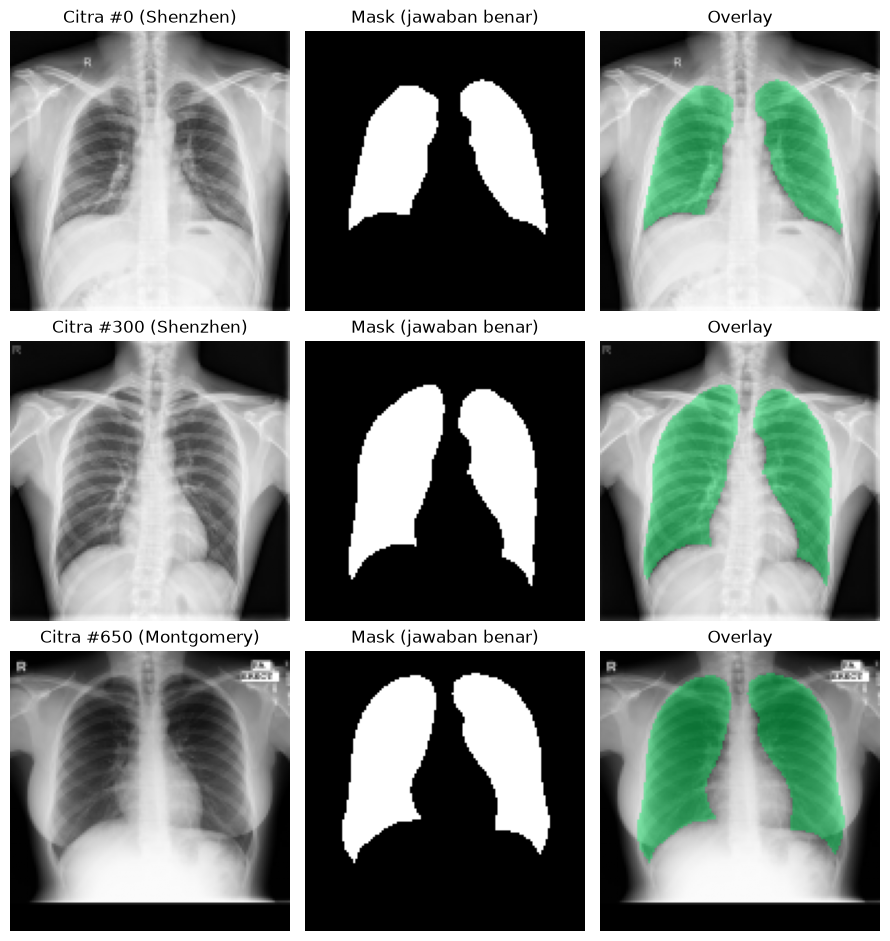

In [4]:
def tampilkan_overlay(ax, citra, mask, warna=(0, 1, 0.4), judul=""):
    # Gambar citra hitam-putih, lalu tempelkan mask berwarna transparan di atasnya
    ax.imshow(citra, cmap="gray")
    lapisan = np.zeros((*mask.shape, 4))
    lapisan[mask == 1] = (*warna, 0.4)          # 0.4 = tingkat transparansi
    ax.imshow(lapisan)
    ax.set_title(judul)
    ax.axis("off")


contoh = [0, 300, 650]                          # tiga citra yang akan dilihat
fig, axes = plt.subplots(3, 3, figsize=(9, 9.5))
for baris, i in enumerate(contoh):
    axes[baris, 0].imshow(citra_semua[i], cmap="gray")
    axes[baris, 0].set_title(f"Citra #{i} ({asal_semua[i]})")
    axes[baris, 1].imshow(mask_semua[i], cmap="gray")
    axes[baris, 1].set_title("Mask (jawaban benar)")
    tampilkan_overlay(axes[baris, 2], citra_semua[i], mask_semua[i], judul="Overlay")
    axes[baris, 0].axis("off"); axes[baris, 1].axis("off")
plt.tight_layout()
plt.show()

### Mask itu sebenarnya hanya tabel angka 0 dan 1
Kita perbesar sepotong kecil mask di **tepi paru** (8 × 8 piksel). Bagi komputer, mask tidak lebih dari kotak-kotak berisi 0 dan 1 — persis seperti kertas berpetak yang kamu warnai di awal kelas tadi.

In [5]:
potongan = mask_semua[0, 60:68, 20:28]     # baris 60–67, kolom 20–27 dari citra #0 (tepi paru kanan pasien)
print(potongan)

[[0 0 0 0 0 1 1 1]
 [0 0 0 0 1 1 1 1]
 [0 0 0 0 1 1 1 1]
 [0 0 0 0 1 1 1 1]
 [0 0 0 0 1 1 1 1]
 [0 0 0 0 1 1 1 1]
 [0 0 0 1 1 1 1 1]
 [0 0 0 1 1 1 1 1]]


---
## Bagian 4 — Cara lama: tanpa deep learning

Di X-ray, paru berisi udara sehingga tampak **gelap**. Ide paling sederhana: *"semua piksel yang lebih gelap dari batas tertentu adalah paru."* Teknik ini disebut **thresholding**.

Tapi bagaimana menilai hasilnya? Kita butuh angka.

### Dice: seberapa tumpang-tindih tebakan dengan jawaban?

$$\text{Dice} = \frac{2 \times |\text{tebakan} \cap \text{jawaban}|}{|\text{tebakan}| + |\text{jawaban}|}$$

Dalam bahasa sehari-hari: **jumlah piksel yang sama-sama ditandai paru, dibagi rata-rata luas kedua area.**
- **Dice = 1** → tebakan persis sama dengan jawaban.
- **Dice = 0** → tidak ada satu piksel pun yang cocok.

Saudara dekatnya adalah **IoU** (*Intersection over Union*): luas irisan dibagi luas gabungan. IoU selalu sedikit lebih kecil dari Dice, tetapi maknanya sama: makin besar makin baik.

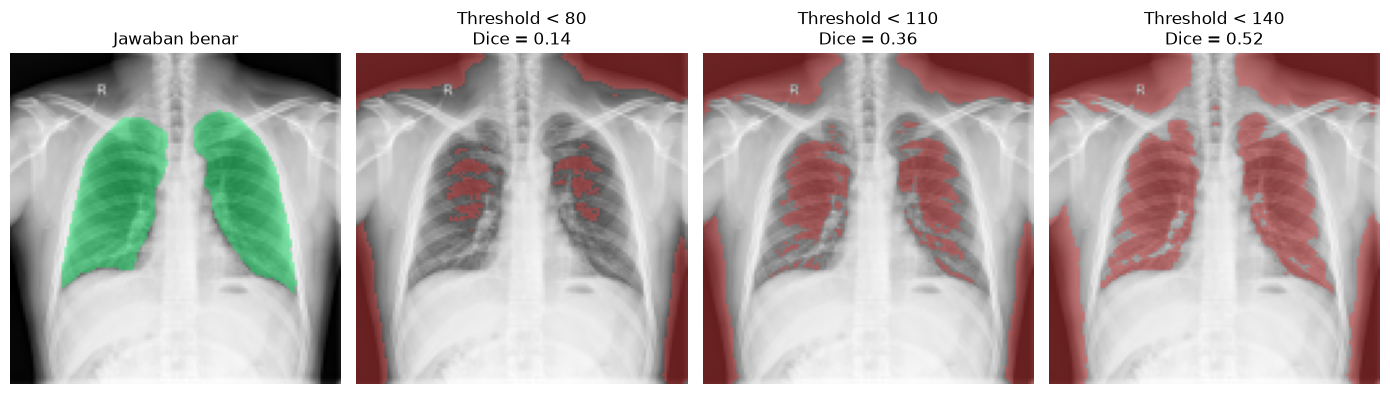

In [6]:
def hitung_dice(tebakan, jawaban):
    # tebakan & jawaban: tabel 0/1 berukuran sama
    irisan = (tebakan * jawaban).sum()
    return (2 * irisan) / (tebakan.sum() + jawaban.sum() + 1e-6)   # 1e-6 mencegah pembagian dengan nol


def hitung_iou(tebakan, jawaban):
    irisan = (tebakan * jawaban).sum()
    gabungan = tebakan.sum() + jawaban.sum() - irisan
    return irisan / (gabungan + 1e-6)


# Coba thresholding pada citra #0 dengan beberapa batas
i = 0
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
tampilkan_overlay(axes[0], citra_semua[i], mask_semua[i], judul="Jawaban benar")
for ax, batas in zip(axes[1:], [80, 110, 140]):
    tebakan = (citra_semua[i] < batas).astype(np.uint8)       # 1 kalau lebih gelap dari batas
    tampilkan_overlay(ax, citra_semua[i], tebakan, warna=(1, 0.3, 0.3),
                      judul=f"Threshold < {batas}\nDice = {hitung_dice(tebakan, mask_semua[i]):.2f}")
plt.tight_layout()
plt.show()

Masalahnya: **latar di luar tubuh juga gelap**, sedangkan bagian paru yang tertutup jantung atau tulang rusuk tampak terang. Aturan sederhana "gelap = paru" tidak cukup. Kita butuh model yang **belajar sendiri** seperti apa paru itu — termasuk bentuk dan letaknya.

Berapa Dice rata-rata thresholding terbaik untuk **seluruh** dataset?

In [7]:
for batas in [80, 110, 140]:
    tebakan = (citra_semua < batas).astype(np.uint8)
    dice_rata = np.mean([hitung_dice(t, m) for t, m in zip(tebakan, mask_semua)])
    print(f"Threshold < {batas}: Dice rata-rata = {dice_rata:.3f}")

Threshold < 80: Dice rata-rata = 0.123
Threshold < 110: Dice rata-rata = 0.254
Threshold < 140: Dice rata-rata = 0.416


> ⏸️ **Jeda — kembali ke slide.** Kita bahas bagaimana deep learning bisa "melihat" bentuk paru, bukan hanya warna piksel.

---
## Bagian 5 — Menyiapkan data untuk PyTorch

Langkah yang sama dengan Pertemuan 9:
1. Ubah angka 0–255 menjadi 0–1 (model lebih mudah belajar dengan angka kecil).
2. Ubah menjadi **tensor** berbentuk `(jumlah citra, kanal, tinggi, lebar)`. X-ray hitam-putih hanya punya **1 kanal** (foto berwarna punya 3: merah, hijau, biru).
3. Bagi menjadi data **latih** (untuk belajar), **validasi** (untuk memantau saat belajar), dan **uji** (ujian akhir, tidak pernah dilihat saat belajar).

In [8]:
# float() → angka desimal, /255 → skala 0..1, unsqueeze(1) → tambahkan dimensi kanal
X = torch.tensor(citra_semua).float().div(255).unsqueeze(1)
Y = torch.tensor(mask_semua).float().unsqueeze(1)
print("Bentuk X:", tuple(X.shape), " Bentuk Y:", tuple(Y.shape))

# Acak urutan lalu bagi: 140 uji, 70 validasi, sisanya latih
urutan = torch.randperm(len(X), generator=torch.Generator().manual_seed(0))
indeks_uji, indeks_val, indeks_latih = urutan[:140], urutan[140:210], urutan[210:]
print(f"Latih: {len(indeks_latih)} | Validasi: {len(indeks_val)} | Uji: {len(indeks_uji)}")

Bentuk X: (704, 1, 128, 128)  Bentuk Y: (704, 1, 128, 128)
Latih: 494 | Validasi: 70 | Uji: 140


---
## Bagian 6 — Membangun U-Net

### Masalahnya
CNN di Pertemuan 9 **meringkas** input sedikit demi sedikit (MaxPool) sampai tinggal satu jawaban. Untuk segmentasi, kita butuh jawaban **seukuran citra aslinya**. Jadi setelah diringkas, hasilnya harus **dibesarkan lagi**.

### Bentuk huruf U
```
citra 128×128 ─► [encoder 1] ──────────────────────────────► [decoder 1] ─► mask 128×128
                      │ ringkas                    perbesar ▲
                      ▼                                     │
                 64×64 [encoder 2] ─────────────► [decoder 2]
                      │ ringkas           perbesar ▲
                      ▼                            │
                 32×32 [encoder 3] ──► [decoder 3]
                      │                     ▲
                      ▼                     │
                 16×16 ──── [dasar U] ──────┘
```
- **Encoder (sisi kiri, turun):** seperti CNN Pertemuan 9. Makin ke bawah, citra makin kecil tetapi model makin paham **konteks**: *"ini rongga dada, paru ada di kiri-kanan jantung."*
- **Decoder (sisi kanan, naik):** membesarkan kembali sampai 128 × 128 untuk **menggambar** mask.
- **Skip connection (panah mendatar):** "contekan" dari encoder ke decoder. Saat diringkas, detail tepi paru hilang; skip connection mengirimkan detail itu langsung ke decoder supaya garis tepi mask tetap tajam.

U-Net diperkenalkan oleh Ronneberger dkk. (2015) **khusus untuk citra biomedis**, justru karena di dunia medis data berlabel biasanya sedikit.

In [9]:
def blok_konvolusi(kanal_masuk, kanal_keluar):
    # Dua kali: konvolusi 3×3 → BatchNorm (menstabilkan belajar) → ReLU
    return nn.Sequential(
        nn.Conv2d(kanal_masuk, kanal_keluar, kernel_size=3, padding=1),
        nn.BatchNorm2d(kanal_keluar),
        nn.ReLU(),
        nn.Conv2d(kanal_keluar, kanal_keluar, kernel_size=3, padding=1),
        nn.BatchNorm2d(kanal_keluar),
        nn.ReLU(),
    )


class UNetMini(nn.Module):
    def __init__(self, k=16):                     # k = jumlah filter di tingkat paling atas
        super().__init__()
        self.ringkas = nn.MaxPool2d(2)            # perkecil 2× (128 → 64 → 32 → 16)

        # Encoder: sisi kiri huruf U
        self.enc1 = blok_konvolusi(1, k)
        self.enc2 = blok_konvolusi(k, 2 * k)
        self.enc3 = blok_konvolusi(2 * k, 4 * k)
        self.dasar = blok_konvolusi(4 * k, 8 * k)

        # Decoder: sisi kanan huruf U. ConvTranspose2d = "perbesar 2×" yang ikut belajar
        self.perbesar3 = nn.ConvTranspose2d(8 * k, 4 * k, kernel_size=2, stride=2)
        self.dec3 = blok_konvolusi(8 * k, 4 * k)
        self.perbesar2 = nn.ConvTranspose2d(4 * k, 2 * k, kernel_size=2, stride=2)
        self.dec2 = blok_konvolusi(4 * k, 2 * k)
        self.perbesar1 = nn.ConvTranspose2d(2 * k, k, kernel_size=2, stride=2)
        self.dec1 = blok_konvolusi(2 * k, k)

        self.keluaran = nn.Conv2d(k, 1, kernel_size=1)   # 1 skor per piksel

    def forward(self, x):
        e1 = self.enc1(x)                         # 128×128
        e2 = self.enc2(self.ringkas(e1))          # 64×64
        e3 = self.enc3(self.ringkas(e2))          # 32×32
        d = self.dasar(self.ringkas(e3))          # 16×16

        # torch.cat([...], dim=1) = tempelkan "contekan" dari encoder (skip connection)
        d = self.dec3(torch.cat([self.perbesar3(d), e3], dim=1))   # 32×32
        d = self.dec2(torch.cat([self.perbesar2(d), e2], dim=1))   # 64×64
        d = self.dec1(torch.cat([self.perbesar1(d), e1], dim=1))   # 128×128
        return self.keluaran(d)


model = UNetMini().to(device)
print(f"Jumlah parameter: {sum(p.numel() for p in model.parameters()):,}")

Jumlah parameter: 483,153


Coba masukkan satu citra. Perhatikan: **ukuran keluaran sama dengan ukuran masukan** — satu skor untuk setiap piksel.

In [10]:
satu_citra = X[:1].to(device)                     # bentuk (1, 1, 128, 128)
with torch.no_grad():
    skor = model(satu_citra)
print("Masukan :", tuple(satu_citra.shape))
print("Keluaran:", tuple(skor.shape), "→ satu skor per piksel")

Masukan : (1, 1, 128, 128)
Keluaran: (1, 1, 128, 128) → satu skor per piksel


---
## Bagian 7 — Melatih model

### Fungsi loss: BCE + Dice
- **BCE** (*Binary Cross-Entropy*): menilai **setiap piksel** satu per satu — *"piksel ini seharusnya paru, kamu yakin berapa persen?"* Ini versi per-piksel dari `CrossEntropyLoss` di Pertemuan 9.
- **Dice loss** = 1 − Dice: menilai **bentuk keseluruhan** mask. Berguna ketika objeknya kecil dibanding latar, karena BCE saja bisa "puas" hanya dengan menebak latar dengan benar.

Model menghasilkan **skor** bebas (bisa negatif). Fungsi `sigmoid` mengubah skor itu menjadi **peluang 0–1**. Peluang > 0,5 kita anggap paru.

### Resep 5 langkah — sama persis dengan Pertemuan 9
Kita bungkus resep latihan dalam satu fungsi `latih()` supaya bisa dipakai ulang di eksperimen augmentasi nanti. Fungsi ini juga bisa menerima `augmentasi` — untuk sekarang dibiarkan kosong.

In [11]:
def dice_batch(peluang, jawaban):
    # Dice untuk setiap citra dalam satu batch (versi tensor dari hitung_dice)
    irisan = (peluang * jawaban).sum(dim=(1, 2, 3))
    return (2 * irisan + 1e-6) / (peluang.sum(dim=(1, 2, 3)) + jawaban.sum(dim=(1, 2, 3)) + 1e-6)


def fungsi_loss(skor, jawaban):
    bce = F.binary_cross_entropy_with_logits(skor, jawaban)   # loss per piksel
    dice = dice_batch(torch.sigmoid(skor), jawaban).mean()     # kemiripan bentuk
    return bce + (1 - dice)


def evaluasi(model, indeks):
    # Dice rata-rata pada sekumpulan citra (mode ujian, tanpa belajar)
    model.eval()
    with torch.no_grad():
        peluang = torch.sigmoid(model(X[indeks].to(device))).cpu()
    tebakan = (peluang > 0.5).float()
    return dice_batch(tebakan, Y[indeks]).mean().item()


def latih(model, indeks, jumlah_epoch, augmentasi=None, indeks_val=None, ukuran_batch=16):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    riwayat = []
    for epoch in range(jumlah_epoch):
        model.train()                                         # mode belajar
        acak = indeks[torch.randperm(len(indeks))]            # acak urutan setiap epoch
        total_loss = 0.0

        for awal in range(0, len(acak), ukuran_batch):
            batch = acak[awal : awal + ukuran_batch]
            citra, jawaban = X[batch], Y[batch]

            if augmentasi is not None:                        # dipakai di Bagian 10
                citra, jawaban = terapkan_augmentasi(augmentasi, citra, jawaban)

            citra, jawaban = citra.to(device), jawaban.to(device)
            skor = model(citra)                               # 1. tebak
            loss = fungsi_loss(skor, jawaban)                 # 2. hitung seberapa salah
            optimizer.zero_grad()                             # 3. bersihkan koreksi lama
            loss.backward()                                   # 4. cari arah perbaikan
            optimizer.step()                                  # 5. perbaiki model
            total_loss += loss.item() * len(batch)

        loss_rata = total_loss / len(indeks)
        if indeks_val is not None:
            dice_val = evaluasi(model, indeks_val)
            riwayat.append((loss_rata, dice_val))
            print(f"Epoch {epoch + 1:2d}/{jumlah_epoch} | loss = {loss_rata:.4f} | Dice validasi = {dice_val:.3f}")
    return riwayat

### Saatnya melatih!
15 epoch memakan waktu beberapa detik di GPU, atau 2–3 menit di CPU.

> **Koneksi lambat atau waktu mepet?** Ubah `PAKAI_MODEL_JADI = True`. Notebook akan mengunduh model yang sudah dilatih sebelumnya (hasilnya setara) sehingga kamu bisa langsung lanjut ke Bagian 8.

In [12]:
PAKAI_MODEL_JADI = False      # ganti True untuk melewati pelatihan
JUMLAH_EPOCH = 15

torch.manual_seed(42)
model = UNetMini().to(device)

if PAKAI_MODEL_JADI:
    file_model = Path("model_unet_paru.pt")
    if not file_model.exists():
        urllib.request.urlretrieve(URL_REPO + "model_unet_paru.pt", file_model)
    model.load_state_dict(torch.load(file_model, map_location=device))
    print("Model jadi berhasil dimuat.")
else:
    mulai = time.time()
    riwayat = latih(model, indeks_latih, JUMLAH_EPOCH, indeks_val=indeks_val)
    print(f"Selesai dalam {time.time() - mulai:.0f} detik.")
    torch.save(model.state_dict(), "model_unet_paru.pt")     # simpan hasil belajar

Epoch  1/15 | loss = 0.8574 | Dice validasi = 0.753


Epoch  2/15 | loss = 0.6089 | Dice validasi = 0.939


Epoch  3/15 | loss = 0.4993 | Dice validasi = 0.945


Epoch  4/15 | loss = 0.4129 | Dice validasi = 0.940


Epoch  5/15 | loss = 0.3451 | Dice validasi = 0.957


...

Epoch 11/15 | loss = 0.1523 | Dice validasi = 0.962


Epoch 12/15 | loss = 0.1415 | Dice validasi = 0.962


Epoch 13/15 | loss = 0.1336 | Dice validasi = 0.961


Epoch 14/15 | loss = 0.1326 | Dice validasi = 0.958


Epoch 15/15 | loss = 0.1269 | Dice validasi = 0.953
Selesai dalam 5 detik.


> ⏸️ **Jeda — kembali ke slide.** Selagi model belajar, kita bahas cara model dinilai saat belajar: loss BCE + Dice, dan dari skor menjadi mask.

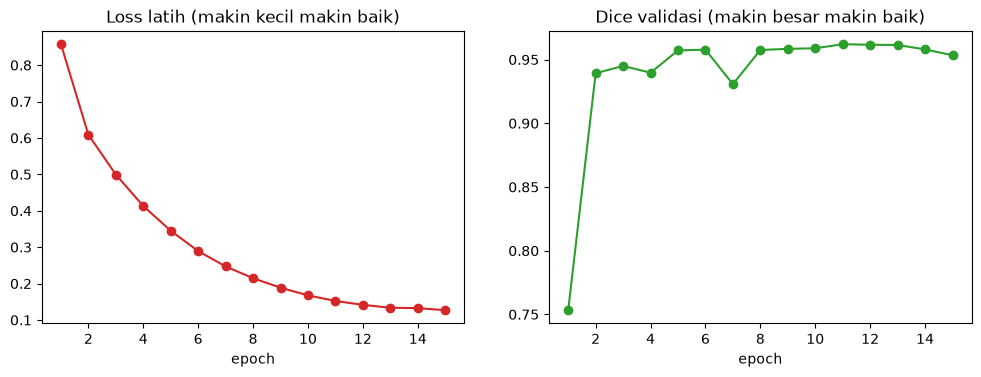

In [13]:
if not PAKAI_MODEL_JADI:
    epoch_ke = range(1, JUMLAH_EPOCH + 1)
    fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(12, 3.8))
    kiri.plot(epoch_ke, [r[0] for r in riwayat], marker="o", color="tab:red")
    kiri.set_title("Loss latih (makin kecil makin baik)")
    kiri.set_xlabel("epoch")
    kanan.plot(epoch_ke, [r[1] for r in riwayat], marker="o", color="tab:green")
    kanan.set_title("Dice validasi (makin besar makin baik)")
    kanan.set_xlabel("epoch")
    plt.show()

---
## Bagian 8 — Ujian: menilai model dengan data uji

In [14]:
model.eval()
with torch.no_grad():
    peluang_uji = torch.sigmoid(model(X[indeks_uji].to(device))).cpu()
tebakan_uji = (peluang_uji > 0.5).float()
jawaban_uji = Y[indeks_uji]

dice_per_citra = dice_batch(tebakan_uji, jawaban_uji)
irisan = (tebakan_uji * jawaban_uji).sum(dim=(1, 2, 3))
gabungan = tebakan_uji.sum(dim=(1, 2, 3)) + jawaban_uji.sum(dim=(1, 2, 3)) - irisan
iou_per_citra = irisan / gabungan

print(f"Dice rata-rata data uji: {dice_per_citra.mean():.3f}")
print(f"IoU  rata-rata data uji: {iou_per_citra.mean():.3f}")
print("(Bandingkan dengan thresholding di Bagian 4!)")

Dice rata-rata data uji: 0.954
IoU  rata-rata data uji: 0.914
(Bandingkan dengan thresholding di Bagian 4!)


### Melihat kesalahannya
Angka saja tidak cukup — **lihat** di mana model salah. Pada kolom terakhir:
- **Hijau** = benar paru (tebakan & jawaban sama-sama paru).
- **Merah** = *false positive*: model bilang paru, padahal bukan.
- **Biru** = *false negative*: paru yang **terlewat** oleh model.

Kita tampilkan 2 citra dengan Dice **terbaik** dan 2 citra dengan Dice **terburuk**.

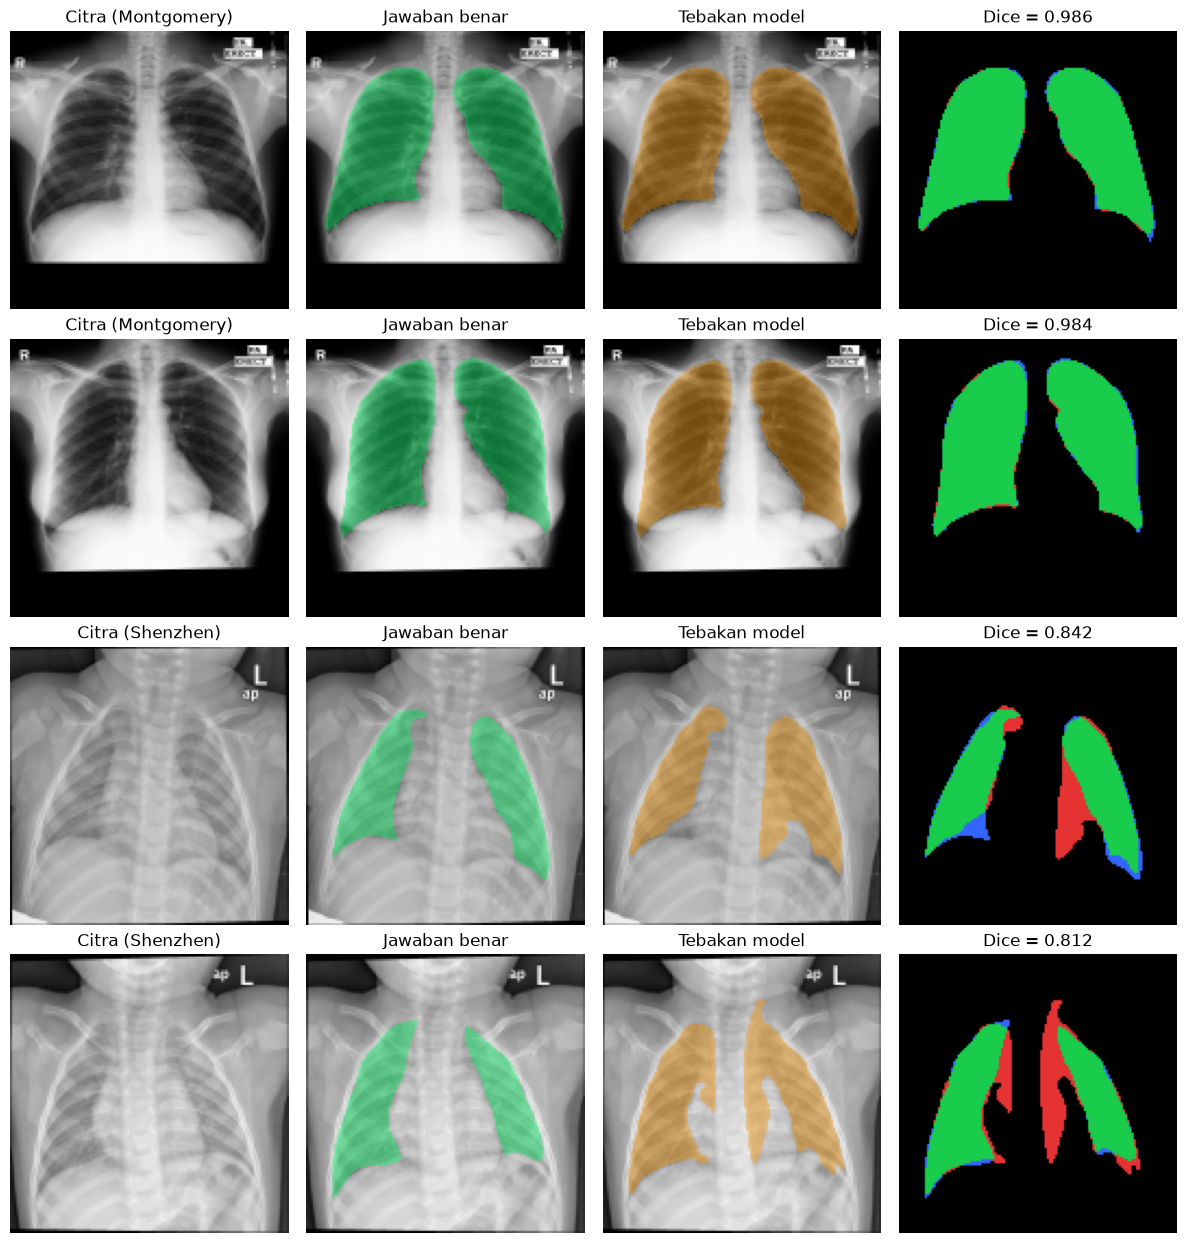

In [15]:
def peta_kesalahan(tebakan, jawaban):
    gambar = np.zeros((*jawaban.shape, 3))
    gambar[(tebakan == 1) & (jawaban == 1)] = (0.1, 0.8, 0.3)    # hijau: benar
    gambar[(tebakan == 1) & (jawaban == 0)] = (0.9, 0.2, 0.2)    # merah: false positive
    gambar[(tebakan == 0) & (jawaban == 1)] = (0.2, 0.4, 1.0)    # biru: false negative
    return gambar


urut = dice_per_citra.argsort()                     # dari Dice terkecil ke terbesar
dipilih = [urut[-1], urut[-2], urut[1], urut[0]]    # 2 terbaik, 2 terburuk

fig, axes = plt.subplots(4, 4, figsize=(12, 12.5))
for baris, j in enumerate(dipilih):
    citra = X[indeks_uji[j], 0].numpy()
    jawaban = jawaban_uji[j, 0].numpy()
    tebakan = tebakan_uji[j, 0].numpy()
    axes[baris, 0].imshow(citra, cmap="gray")
    axes[baris, 0].set_title(f"Citra ({asal_semua[indeks_uji[j]]})")
    tampilkan_overlay(axes[baris, 1], citra, jawaban, judul="Jawaban benar")
    tampilkan_overlay(axes[baris, 2], citra, tebakan, warna=(1, 0.6, 0), judul="Tebakan model")
    axes[baris, 3].imshow(peta_kesalahan(tebakan, jawaban))
    axes[baris, 3].set_title(f"Dice = {dice_per_citra[j]:.3f}")
    for ax in axes[baris]:
        ax.axis("off")
plt.tight_layout()
plt.show()

### Batas 0,5 itu bukan harga mati
Model memberi **peluang** 0–1 untuk setiap piksel. Batas 0,5 hanyalah kesepakatan. Kalau batas dinaikkan, model makin "pelit" menandai paru; kalau diturunkan, makin "royal". Coba lihat pengaruhnya terhadap Dice:

In [16]:
for batas in [0.1, 0.3, 0.5, 0.7, 0.9]:
    t = (peluang_uji > batas).float()
    print(f"Batas peluang {batas:.1f} → Dice = {dice_batch(t, jawaban_uji).mean():.3f}")

Batas peluang 0.1 → Dice = 0.940
Batas peluang 0.3 → Dice = 0.952
Batas peluang 0.5 → Dice = 0.954
Batas peluang 0.7 → Dice = 0.955
Batas peluang 0.9 → Dice = 0.950


> ⏸️ **Jeda — kembali ke slide.** Model kita bagus pada data uji. Tapi apakah tetap bagus kalau dipakai di rumah sakit lain? Kita bahas augmentasi data.

---
## Bagian 9 — Augmentasi data

**Augmentasi** = membuat variasi baru dari citra latih yang sudah ada: diputar sedikit, digeser, diperbesar, dibuat lebih terang atau lebih gelap. Model jadi berlatih dengan "soal" yang lebih beragam tanpa kita perlu mengumpulkan data baru.

### Aturan terpenting: citra dan mask harus berubah bersamaan
Kalau citra diputar 10°, mask juga **wajib** diputar 10° dengan cara yang persis sama. Kalau tidak, model belajar dari jawaban yang salah.

`torchvision.transforms.v2` mengurus ini untuk kita, **asalkan** kita memberi tahu mana citra dan mana mask lewat `tv_tensors.Image` dan `tv_tensors.Mask`. Perubahan kecerahan/kontras otomatis **hanya** diterapkan pada citra (mask tidak punya "kecerahan").

### Augmentasi harus masuk akal secara klinis
Kita **tidak** memakai *flip* kiri-kanan: X-ray yang dicerminkan akan menampilkan jantung di sebelah kanan — kondisi langka (*dextrocardia*) yang tidak mewakili pasien pada umumnya. Rotasi pun dibatasi kecil (±10°), karena pasien difoto dalam posisi berdiri tegak.

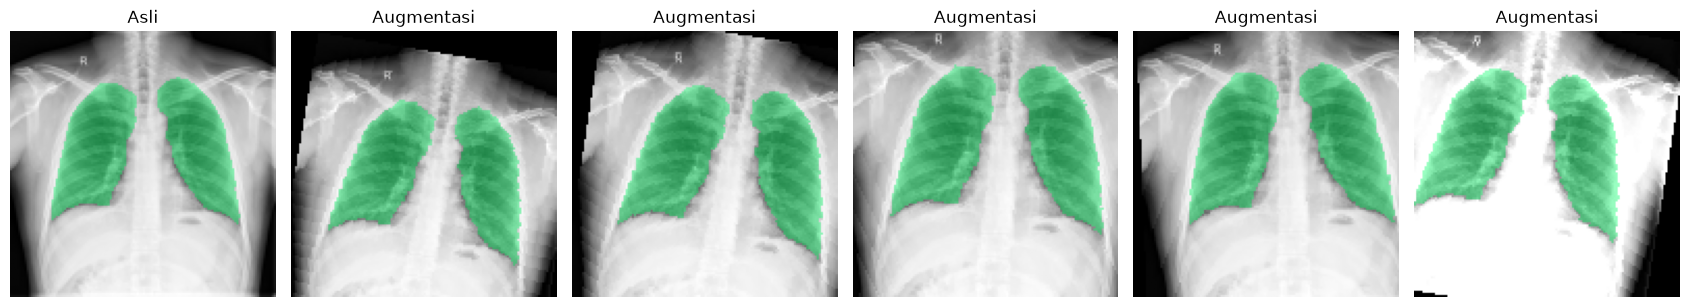

In [17]:
aug_geometri = v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.85, 1.15))  # putar, geser, perbesar
aug_intensitas = v2.ColorJitter(brightness=0.5, contrast=0.5)                         # terang/gelap, kontras
aug_lengkap = v2.Compose([aug_geometri, aug_intensitas])


def terapkan_augmentasi(augmentasi, citra, jawaban):
    # Augmentasi setiap pasangan (citra, mask) dalam batch; acakannya berbeda untuk setiap pasangan
    hasil_citra, hasil_mask = [], []
    for c, m in zip(citra, jawaban):
        c_baru, m_baru = augmentasi(tv_tensors.Image(c), tv_tensors.Mask(m))
        hasil_citra.append(c_baru)
        hasil_mask.append(m_baru)
    return torch.stack(hasil_citra), torch.stack(hasil_mask)


# Lihat 5 variasi acak dari citra yang sama
i = 0
fig, axes = plt.subplots(1, 6, figsize=(17, 3.2))
tampilkan_overlay(axes[0], X[i, 0].numpy(), Y[i, 0].numpy(), judul="Asli")
for ax in axes[1:]:
    c, m = terapkan_augmentasi(aug_lengkap, X[i : i + 1], Y[i : i + 1])
    tampilkan_overlay(ax, c[0, 0].numpy(), m[0, 0].numpy(), judul="Augmentasi")
plt.tight_layout()
plt.show()

Mask (hijau) selalu ikut bergerak bersama paru. Sekarang lihat apa yang terjadi kalau kita **lupa** membungkus mask dengan `tv_tensors.Mask`:

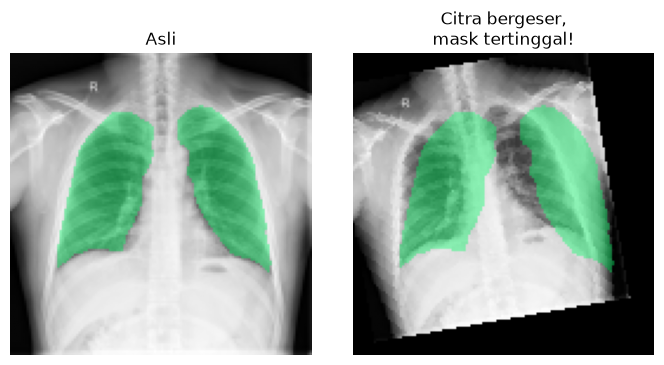

In [18]:
torch.manual_seed(3)
c_salah, m_salah = aug_geometri(tv_tensors.Image(X[i]), Y[i])     # mask TIDAK dibungkus

fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
tampilkan_overlay(axes[0], X[i, 0].numpy(), Y[i, 0].numpy(), judul="Asli")
tampilkan_overlay(axes[1], c_salah[0].numpy(), m_salah[0].numpy(), judul="Citra bergeser,\nmask tertinggal!")
plt.tight_layout()
plt.show()

Tidak ada pesan error sama sekali — kode tetap berjalan, tetapi model akan belajar dari jawaban yang salah. **Selalu cek augmentasimu secara visual** sebelum melatih model.

---
## Bagian 10 — Eksperimen: model dari rumah sakit lain

### Skenario
Sebuah rumah sakit di **Shenzhen** punya model segmentasi paru yang dilatih dengan **hanya 20 citra** miliknya. Model ini lalu dipakai di rumah sakit **Montgomery** di Amerika — mesin X-ray berbeda, pengaturan berbeda, pasien berbeda.

Apakah model masih bekerja? Dan apakah augmentasi bisa membantu?

Pertama, lihat dulu perbedaan citra dari kedua rumah sakit:

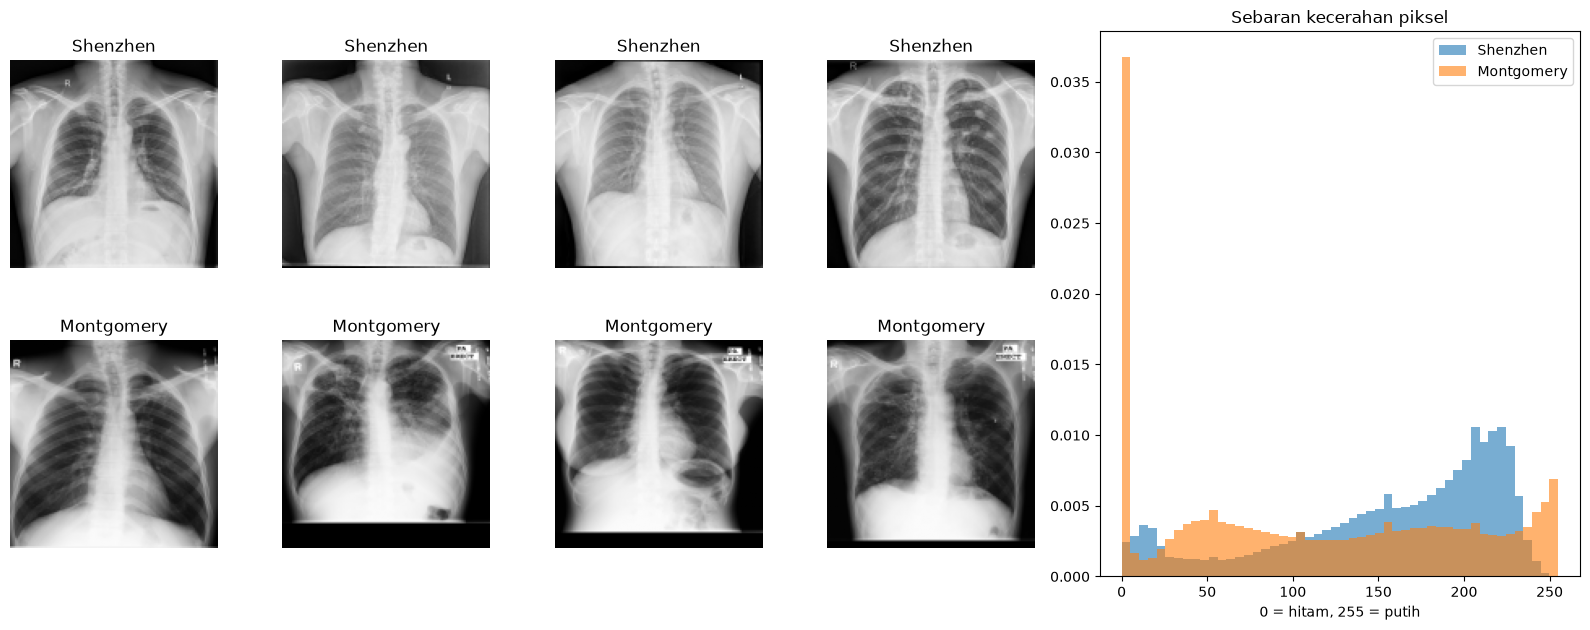

In [19]:
indeks_shenzhen = torch.tensor(np.where(asal_semua == "Shenzhen")[0])
indeks_montgomery = torch.tensor(np.where(asal_semua == "Montgomery")[0])

fig = plt.figure(figsize=(16, 6.4))
kotak = fig.add_gridspec(2, 6)                      # 2 baris × 6 kolom; 2 kolom terakhir untuk histogram
for kolom in range(4):
    for baris, (rs, indeks) in enumerate([("Shenzhen", indeks_shenzhen), ("Montgomery", indeks_montgomery)]):
        ax = fig.add_subplot(kotak[baris, kolom])
        ax.imshow(citra_semua[indeks[kolom]], cmap="gray", vmin=0, vmax=255)
        ax.set_title(rs)
        ax.axis("off")

# Histogram: sebaran tingkat kecerahan piksel di setiap rumah sakit
ax = fig.add_subplot(kotak[:, 4:])
ax.hist(citra_semua[indeks_shenzhen].ravel(), bins=50, alpha=0.6, density=True, label="Shenzhen")
ax.hist(citra_semua[indeks_montgomery].ravel(), bins=50, alpha=0.6, density=True, label="Montgomery")
ax.set_title("Sebaran kecerahan piksel")
ax.set_xlabel("0 = hitam, 255 = putih")
ax.legend()
plt.tight_layout()
plt.show()

Citra dari kedua rumah sakit punya **sebaran kecerahan dan kontras yang berbeda**. Bagi kita masih sama-sama X-ray dada; bagi model yang hanya pernah melihat 20 citra Shenzhen, citra Montgomery bisa terasa "asing".

### Menjalankan eksperimen
Kita ambil 20 citra Shenzhen dari data latih, lalu melatih model baru dari nol dengan data yang sama persis — bedanya hanya augmentasi:
1. **Tanpa** augmentasi.
2. Augmentasi **geometri** saja (putar, geser, perbesar).
3. Augmentasi **intensitas** saja (kecerahan, kontras).

Setiap model diuji di citra Shenzhen (rumah sakit yang sama) **dan** di seluruh citra Montgomery (rumah sakit lain).

Dengan data sesedikit 20 citra, hasil satu kali latihan bisa kebetulan bagus atau kebetulan jelek. Karena itu setiap skenario kita ulang **3 kali** dengan 20 citra yang berbeda, lalu kita ambil **rata-ratanya**. Ini kebiasaan baik dalam eksperimen: jangan percaya hasil satu kali jalan.

In [20]:
# 20 citra Shenzhen dari data latih (tidak ada yang berasal dari data uji)
shenzhen_latih = indeks_latih[torch.from_numpy(asal_semua[indeks_latih.numpy()] == "Shenzhen")]
shenzhen_uji = indeks_uji[torch.from_numpy(asal_semua[indeks_uji.numpy()] == "Shenzhen")]

skenario = {
    "Tanpa augmentasi": None,
    "Geometri": aug_geometri,
    "Intensitas": aug_intensitas,
}
JUMLAH_ULANGAN = 3
hasil = {}
mulai = time.time()
for nama, augmentasi in skenario.items():
    catatan = []
    for ulangan in range(JUMLAH_ULANGAN):
        # Pilih 20 citra Shenzhen secara acak; ulangan ke-n memakai 20 citra yang sama di semua skenario
        pilih = torch.randperm(len(shenzhen_latih), generator=torch.Generator().manual_seed(ulangan))[:20]
        torch.manual_seed(ulangan)                       # titik awal model juga sama antar-skenario
        model_kecil = UNetMini().to(device)
        latih(model_kecil, shenzhen_latih[pilih], jumlah_epoch=40, augmentasi=augmentasi)
        catatan.append((evaluasi(model_kecil, shenzhen_uji), evaluasi(model_kecil, indeks_montgomery)))
    hasil[nama] = np.array(catatan)                      # bentuk (3 ulangan, 2 rumah sakit)
    print(f"{nama:17s} | Dice Montgomery tiap ulangan = {np.round(hasil[nama][:, 1], 3)} "
          f"| rata-rata Shenzhen = {hasil[nama][:, 0].mean():.3f}, Montgomery = {hasil[nama][:, 1].mean():.3f}")
print(f"Total waktu: {time.time() - mulai:.0f} detik")

Tanpa augmentasi  | Dice Montgomery tiap ulangan = [0.257 0.875 0.511] | rata-rata Shenzhen = 0.923, Montgomery = 0.548


Geometri          | Dice Montgomery tiap ulangan = [0.735 0.792 0.526] | rata-rata Shenzhen = 0.923, Montgomery = 0.684


Intensitas        | Dice Montgomery tiap ulangan = [0.856 0.914 0.922] | rata-rata Shenzhen = 0.932, Montgomery = 0.897
Total waktu: 8 detik


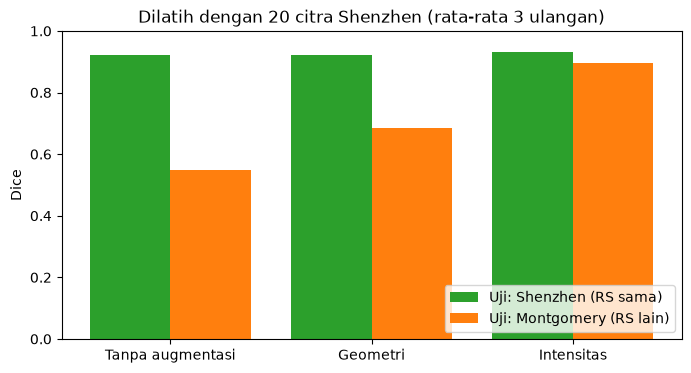

In [21]:
nama_skenario = list(hasil)
posisi = np.arange(len(nama_skenario))
plt.figure(figsize=(8, 4))
plt.bar(posisi - 0.2, [hasil[n][:, 0].mean() for n in nama_skenario], width=0.4, label="Uji: Shenzhen (RS sama)", color="tab:green")
plt.bar(posisi + 0.2, [hasil[n][:, 1].mean() for n in nama_skenario], width=0.4, label="Uji: Montgomery (RS lain)", color="tab:orange")
plt.xticks(posisi, nama_skenario)
plt.ylabel("Dice")
plt.ylim(0, 1)
plt.title(f"Dilatih dengan 20 citra Shenzhen (rata-rata {JUMLAH_ULANGAN} ulangan)")
plt.legend(loc="lower right")
plt.show()

### Apa yang kita pelajari?
- Di rumah sakit yang **sama**, model dari 20 citra pun sudah bagus.
- Di rumah sakit **lain**, kinerja model **tanpa augmentasi turun drastis**. Inilah masalah nyata AI medis yang disebut ***domain shift***: model bagus di tempat asalnya, gagal di tempat lain.
- Augmentasi **intensitas** paling membantu — karena perbedaan utama kedua rumah sakit memang terletak pada kecerahan dan kontras (lihat histogram tadi).
- Augmentasi **geometri** hasilnya tidak menentu: kadang sedikit membantu, kadang malah merugikan. Memutar dan menggeser citra tidak menyelesaikan masalah yang sebenarnya (perbedaan kecerahan).

> **Pelajaran utama:** augmentasi bukan "semakin banyak semakin baik". Pilih augmentasi yang **meniru variasi nyata** yang akan dihadapi model di lapangan.

Perhatikan juga angka tiap ulangan: tanpa augmentasi, hasilnya **naik-turun jauh** tergantung 20 citra mana yang kebetulan terpilih. Augmentasi intensitas membuat model bukan hanya lebih akurat, tetapi juga lebih **stabil**.

---
## Rangkuman

| Konsep | Intinya |
|---|---|
| Segmentasi | Klasifikasi untuk **setiap piksel**; hasilnya berupa mask |
| Dice & IoU | Mengukur tumpang-tindih tebakan dengan jawaban; 1 = sempurna |
| U-Net | Encoder meringkas (konteks), decoder membesarkan (menggambar), skip connection menjaga detail tepi |
| Loss BCE + Dice | Menilai per piksel **dan** bentuk keseluruhan |
| Augmentasi | Citra & mask harus berubah bersama; pilih yang masuk akal secara klinis dan meniru variasi nyata |
| Domain shift | Model bisa gagal di rumah sakit lain — selalu uji di data dari sumber berbeda |

### Untuk dicoba sendiri
1. Ganti jumlah citra latih di Bagian 10 dari 20 menjadi 5 atau 100 (ubah angka `[:20]`). Apakah augmentasi masih membantu?
2. Coba `aug_lengkap` (geometri + intensitas) di eksperimen Bagian 10.
3. Tambahkan `v2.RandomHorizontalFlip()` ke augmentasi. Apa yang terjadi pada hasil di Montgomery? Apakah augmentasi ini masuk akal secara klinis?
4. Ubah `UNetMini(k=16)` menjadi `k=8` (model lebih kecil) atau `k=32` (lebih besar). Bagaimana Dice dan waktu latihnya?

### Referensi
- Ronneberger, O., Fischer, P., & Brox, T. (2015). *U-Net: Convolutional Networks for Biomedical Image Segmentation*. MICCAI. [arXiv:1505.04597](https://arxiv.org/abs/1505.04597)
- Jaeger, S., dkk. (2014). *Two public chest X-ray datasets for computer-aided screening of pulmonary diseases*. Quantitative Imaging in Medicine and Surgery, 4(6), 475–477.
- Candemir, S., dkk. (2014). *Lung segmentation in chest radiographs using anatomical atlases with nonrigid registration*. IEEE Transactions on Medical Imaging, 33(2), 577–590.
- Dataset Kaggle: [Chest X-ray Dataset for Tuberculosis Segmentation](https://www.kaggle.com/datasets/iamtapendu/chest-x-ray-lungs-segmentation) (Apache 2.0).